# SET50: stock-price forecasts and portfolio decisions

This notebook examines the real-price study: three neural models, six portfolio sizes, a target-return Markowitz optimizer, and transaction costs. The historical universe is the January 2015 SET50 cohort. Only 41 of its 50 histories met the documented coverage policy; this limitation matters when interpreting results.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
OUT = ROOT / "reports/set50"
manifest = json.loads((ROOT / "data/set50/manifest.json").read_text())
print("{:,} trading dates; {} included stocks".format(manifest["observations"], len(manifest["included_assets"])))
print(manifest["first_date"], "to", manifest["last_date"])
display(pd.read_csv(ROOT / "data/set50/cleaning_audit.csv").head())

1,462 trading dates; 41 included stocks
2015-01-05 to 2020-12-30


,symbol,observed,missing,coverage,forward_filled,large_return_flags,included,exclusion_reason
0,ADVANC,1462,0,1.000000,0,0,True,NaN
1,AOT,1462,0,1.000000,0,0,True,NaN
2,BANPU,1018,444,0.696306,0,0,False,coverage_below_threshold
3,BAY,1462,0,1.000000,0,0,True,NaN
4,BBL,1462,0,1.000000,0,0,True,NaN


## 1. Inspect exclusions before performance

The list was published before the study began, but retained-data availability is assessed today. Missing delisted or reorganized histories and the full-period coverage filter can bias results. No successor company was invented to repair a missing series.

In [2]:
downloads = pd.read_csv(ROOT / "data/set50/download_audit.csv")
display(downloads.loc[downloads.status != "downloaded", ["symbol", "provider_symbol", "status"]])
cleaning = pd.read_csv(ROOT / "data/set50/cleaning_audit.csv")
display(cleaning.loc[~cleaning.included, ["symbol", "coverage", "exclusion_reason"]])

,symbol,provider_symbol,status
9,BIGC,BIGC.BK,unavailable
18,DTAC,DTAC.BK,unavailable
20,GLOW,GLOW.BK,unavailable
21,HEMRAJ,HEMRAJ.BK,unavailable
23,INTUCH,INTUCH.BK,unavailable
33,PS,PS.BK,unavailable
38,ROBINS,ROBINS.BK,unavailable
39,SCB,SCB.BK,unavailable


,symbol,coverage,exclusion_reason
2,BANPU,0.696306,coverage_below_threshold


## 2. Model architecture

R-CNN means a convolutional state refined repeatedly using the same recurrent kernel. The resulting temporal features enter a BiLSTM. Both directions see only the historical window. The response is a terminal log-price ratio, transformed back to an adjusted stock price.

In [3]:
from markowitz.price_forecast import build_price_network
model = build_price_network(len(manifest["included_assets"]), "rcnn_bilstm")
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

PriceNetwork(
  (rcnn): RecurrentConvolution(
    (input_conv): Conv1d(41, 16, kernel_size=(3,), stride=(1,), padding=(1,))
    (recurrent_conv): Conv1d(16, 16, kernel_size=(3,), stride=(1,), padding=(1,), bias=False)
  )
  (lstm): LSTM(16, 16, batch_first=True, bidirectional=True)
  (head): Linear(in_features=32, out_features=41, bias=True)
)
Trainable parameters: 8457


## 3. All six portfolio sizes

The requested annual expected-return target is 8%, with a 35% position cap. Each run minimizes variance subject to that return constraint; infeasible targets are lowered and logged. The same forecasts are reused across portfolio sizes.

In [4]:
metrics = pd.read_csv(OUT / "portfolio_metrics.csv")
main = metrics[metrics.strategy == "Forecast Markowitz"]
assert set(main.top_k) == set(range(5, 11))
assert len(main) == 18
display(main.pivot(index="top_k", columns="model", values="sharpe").round(3))
display(main[main.top_k == 10][["model", "total_return", "mean_daily_return", "mean_annual_return", "volatility", "sharpe", "max_drawdown", "target_clipped_count"]].round(4))

model,bilstm,lstm,rcnn_bilstm
top_k,,,
5,0.654,0.566,0.597
6,0.500,0.431,0.406
7,0.459,0.514,0.219
8,0.455,0.430,0.239
9,0.427,0.533,0.183
10,0.392,0.430,0.165


,model,total_return,mean_daily_return,mean_annual_return,volatility,sharpe,max_drawdown,target_clipped_count
22,lstm,0.4694,0.0004,0.0961,0.1775,0.4299,-0.3908,2
46,bilstm,0.4281,0.0004,0.0909,0.1815,0.3916,-0.3861,3
70,rcnn_bilstm,0.1726,0.0002,0.0475,0.1685,0.1646,-0.3950,1


## 4. Price errors and portfolio outcomes

The no-change baseline predicts the last observed price. Evaluate it alongside price MAE/RMSE and MAPE. A good price forecast does not automatically imply a useful ranking or a better portfolio.

,model,asset_predictions,price_rmse_adjusted_thb,price_mae_adjusted_thb,price_mape,no_change_price_mape,direction_accuracy
0,lstm,2337,5.2239,2.6846,0.0643,0.0607,0.5036
1,bilstm,2337,5.3177,2.7343,0.0653,0.0607,0.5006
2,rcnn_bilstm,2337,5.2503,2.7101,0.0653,0.0607,0.4951


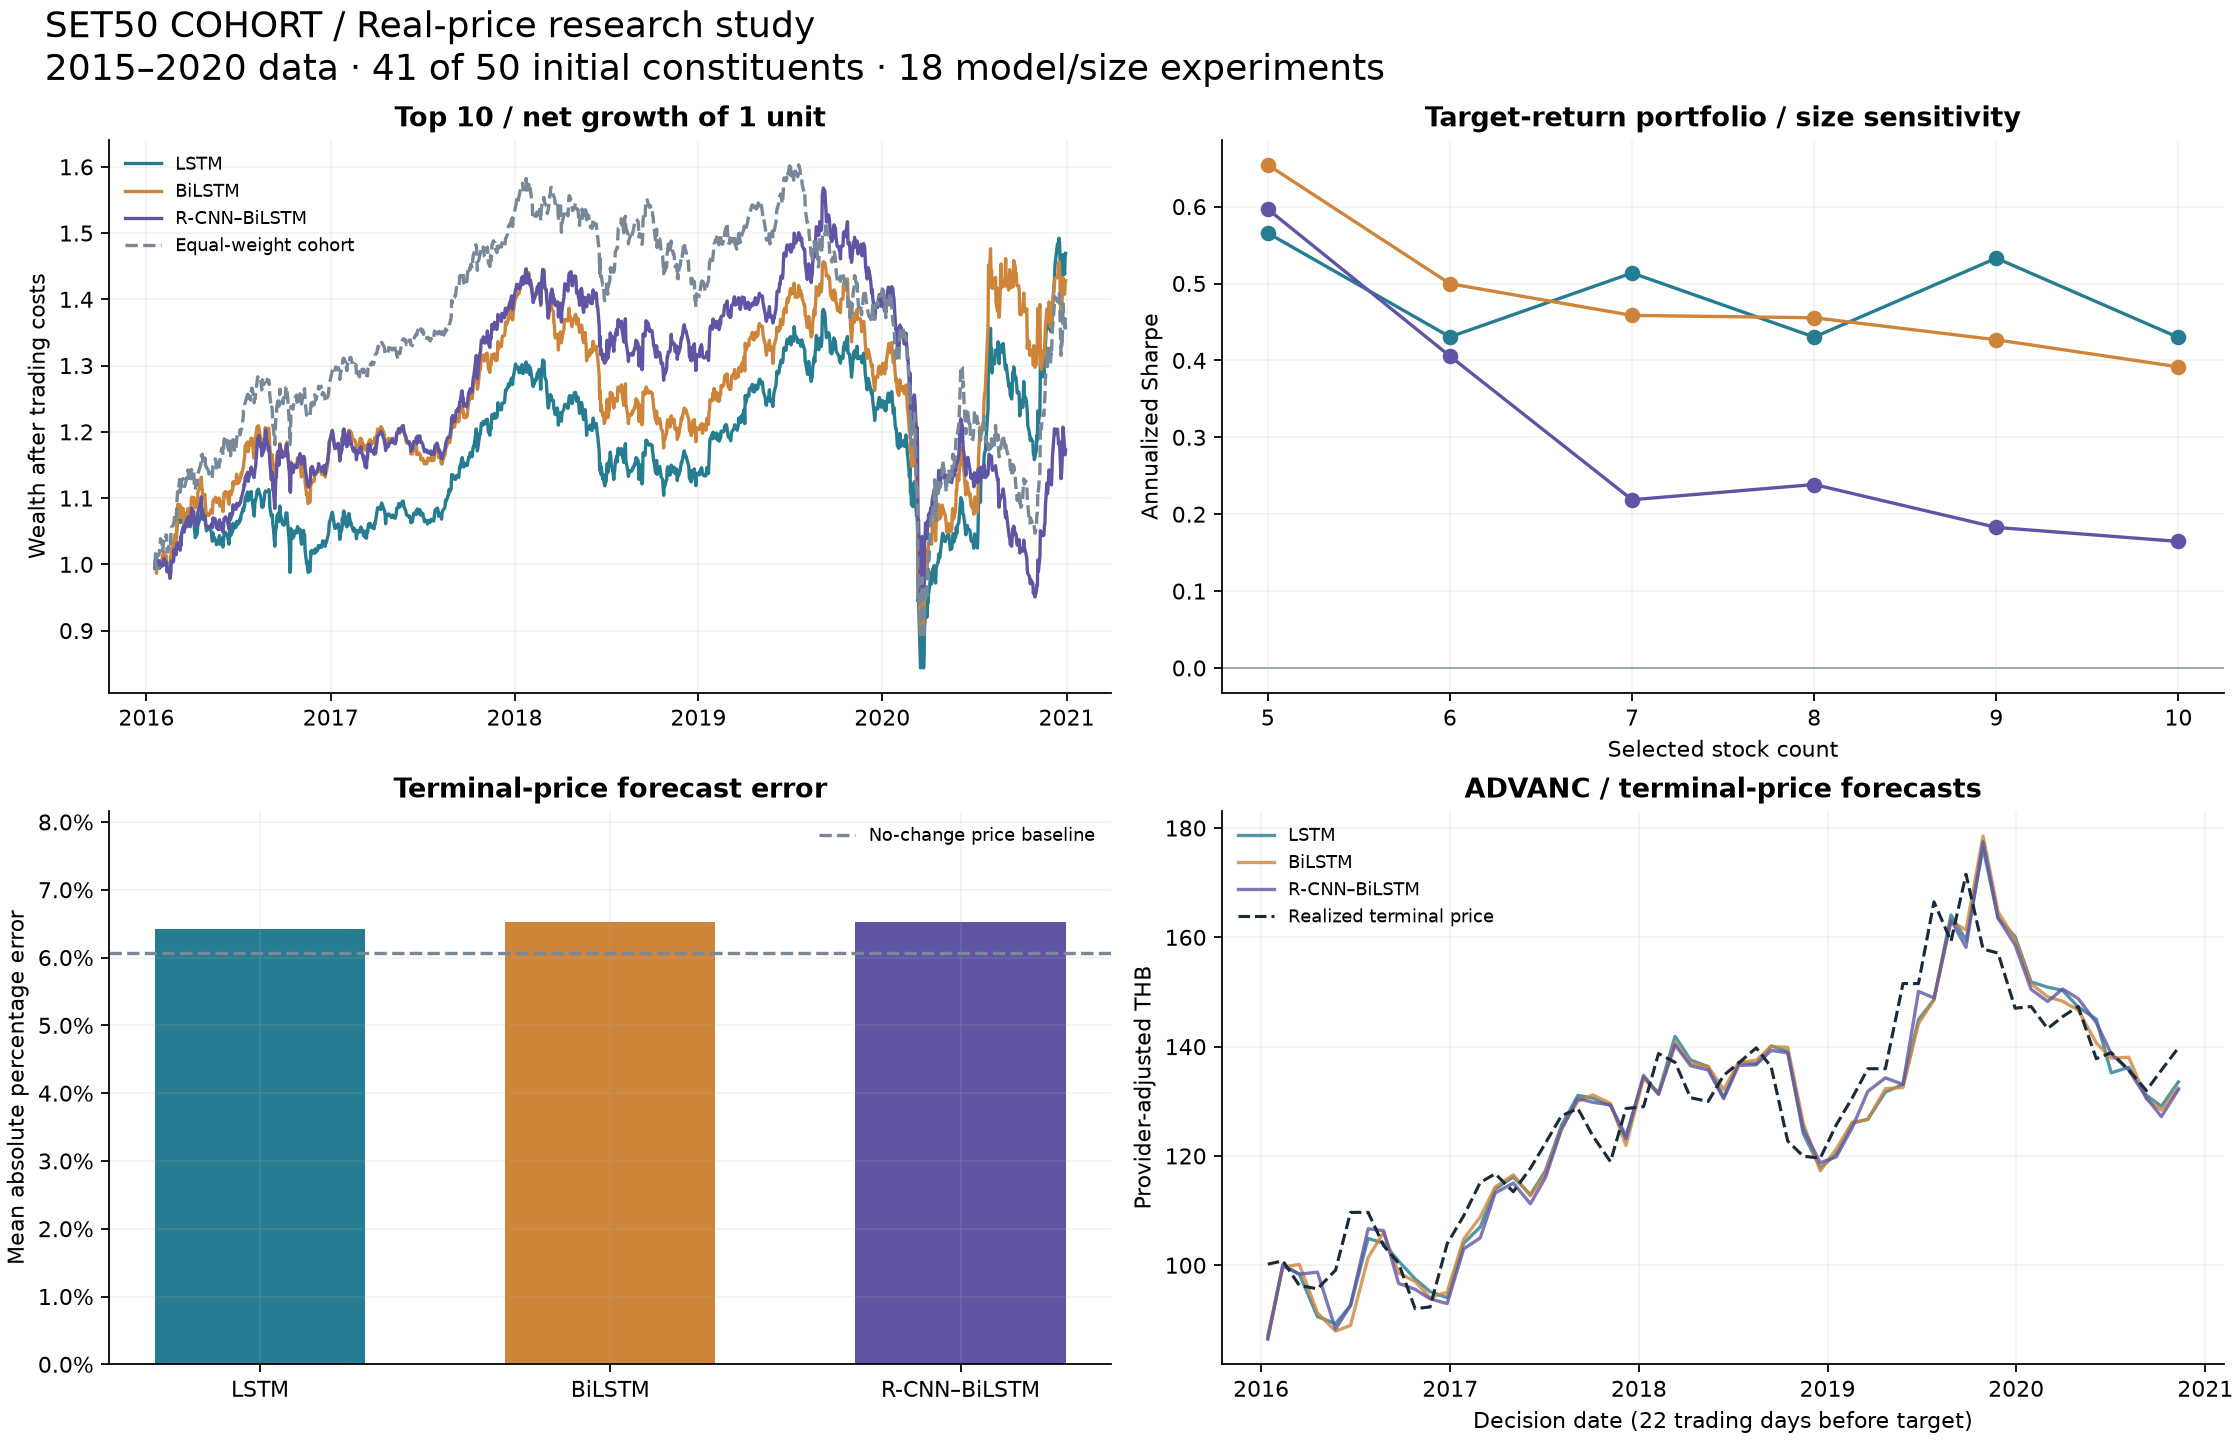

In [5]:
display(pd.read_csv(OUT / "price_metrics.csv").round(4))
display(Image(filename=str(OUT / "overview.png")))

## 5. Audit the target constraint

A target clipping flag is a disclosure, not a successful 8% target. Expected returns here are model estimates; realized returns can be much lower.

In [6]:
trades = pd.read_csv(OUT / "rcnn_bilstm/k10/trades.csv")
targeted = trades[trades.strategy == "Forecast Markowitz"]
assert (targeted.expected_return >= targeted.effective_target - 1e-7).all()
display(targeted[["execution_date", "requested_target", "effective_target", "expected_return", "target_clipped", "cost_fraction"]].head(10))

,execution_date,requested_target,effective_target,expected_return,target_clipped,cost_fraction
2,2016-01-15,0.08,0.08,0.080000,False,0.001000
6,2016-02-15,0.08,0.08,0.216148,False,0.001550
10,2016-03-16,0.08,0.08,0.145542,False,0.000959
14,2016-04-20,0.08,0.08,0.080000,False,0.001867
18,2016-05-25,0.08,0.08,0.211698,False,0.001490
22,2016-06-23,0.08,0.08,0.279145,False,0.000378
26,2016-07-27,0.08,0.08,0.541186,False,0.001633
30,2016-08-26,0.08,0.08,0.548034,False,0.000802
34,2016-09-26,0.08,0.08,0.447347,False,0.001467
38,2016-10-26,0.08,0.08,0.455471,False,0.000442


## 6. Replay the latest hybrid checkpoint

The replay uses only prices observed by the saved decision date. Run `python scripts/download_set50.py` first if the local adjusted-price panel is absent. Asset order and normalization parameters are saved in the checkpoint.

In [7]:
import torch
from markowitz.data import load_prices
from markowitz.price_forecast import predict_from_checkpoint
checkpoint = torch.load(OUT / "rcnn_bilstm/latest_model.pt", weights_only=True)
local_prices = ROOT / "data/set50/adjusted_prices.csv"
if local_prices.exists():
    prices = load_prices(local_prices)[checkpoint["asset_names"]]
    observed = prices.loc[:checkpoint["decision_date"]]
    prediction = predict_from_checkpoint(checkpoint, observed.to_numpy())
    saved = pd.read_csv(OUT / "rcnn_bilstm/price_forecasts.csv")
    latest = saved[saved.decision_date == checkpoint["decision_date"]].set_index("asset").loc[checkpoint["asset_names"]]
    np.testing.assert_allclose(prediction, latest.predicted_price, rtol=1e-5)
    display(pd.DataFrame({"replayed_price": prediction, "saved_price": latest.predicted_price.to_numpy()}, index=checkpoint["asset_names"]).head())
    print("Checkpoint replay matches the recorded forecast.")
else:
    print("Download the price panel to replay this checkpoint. Saved study outputs above remain available offline.")

,replayed_price,saved_price
ADVANC,139.510583,139.510583
AOT,60.790505,60.790505
BAY,22.312368,22.312368
BBL,93.947859,93.947859
BCP,14.581796,14.581796


Checkpoint replay matches the recorded forecast.


## Interpretation

This completes the implemented price-forecasting and allocation workflow, but it does not remove data limitations. The fixed 41-stock coverage subset, present-vintage adjustments, one period and one seed prevent claims of a survivorship-free or statistically established investment edge. The methodology and source audits are part of the result, not optional footnotes.